# Proyecto: recuperación de oro

**Objetivo.** Construir un modelo que prediga el **coeficiente de recuperación de oro** en dos etapas del proceso (`rougher.output.recovery` y `final.output.recovery`) a partir de las mediciones disponibles *antes* de que el proceso termine.

**Métrica.** sMAPE final = 25 % · sMAPE(rougher) + 75 % · sMAPE(final). Menor es mejor.

**Contenido**
1. Preparación de los datos
2. Análisis de los datos
3. Construcción del modelo (validación sin fuga temporal, búsqueda de hiperparámetros y modelo de referencia)
4. Conclusiones

> Nota de lectura: tras cada bloque de código hay una interpretación escrita. Las cifras concretas se imprimen desde el código para que el texto siempre corresponda a los resultados de la última ejecución.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from sklearn.model_selection import TimeSeriesSplit, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import make_scorer

RANDOM_STATE = 12345
pd.set_option('display.max_columns', 60)

## 1. Preparación de los datos

### 1.1 Carga y revisión inicial

Cargo los tres archivos (entrenamiento, prueba y completo), convierto `date` a fecha y **ordeno cada tabla cronológicamente**: los datos son una serie de tiempo y el orden importa para la validación más adelante.

In [2]:
train = pd.read_csv('data/gold_recovery_train.csv')
test = pd.read_csv('data/gold_recovery_test.csv')
full = pd.read_csv('data/gold_recovery_full.csv')

for df in (train, test, full):
    df['date'] = pd.to_datetime(df['date'])

train = train.sort_values('date').reset_index(drop=True)
test = test.sort_values('date').reset_index(drop=True)
full = full.sort_values('date').reset_index(drop=True)

print("Tamaño de train:", train.shape)
print("Tamaño de test:", test.shape)
print("Tamaño de full:", full.shape)
print("Rango de fechas train:", train['date'].min(), "->", train['date'].max())
print("Rango de fechas test: ", test['date'].min(), "->", test['date'].max())

print("\nInformación del dataset de entrenamiento:")
train.info()

Tamaño de train: (16860, 87)
Tamaño de test: (5856, 53)
Tamaño de full: (22716, 87)
Rango de fechas train: 2016-01-15 00:00:00 -> 2018-08-18 10:59:59
Rango de fechas test:  2016-09-01 00:59:59 -> 2017-12-31 23:59:59

Información del dataset de entrenamiento:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16860 entries, 0 to 16859
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype         
---  ------                                              --------------  -----         
 0   date                                                16860 non-null  datetime64[ns]
 1   final.output.concentrate_ag                         16788 non-null  float64       
 2   final.output.concentrate_pb                         16788 non-null  float64       
 3   final.output.concentrate_sol                        16490 non-null  float64       
 4   final.output.concentrate_au                         16789 non-null  float64       
 5   final.outpu

In [3]:
na_pct = (train.isna().mean() * 100).sort_values(ascending=False)
print("Porcentaje de valores ausentes (15 columnas con más ausentes):")
print(na_pct.head(15).round(2))
print(f"\nColumnas con al menos un ausente: {(na_pct > 0).sum()} de {train.shape[1]}")

print("\nDuplicados:")
print("Train:", train.duplicated().sum())
print("Test:", test.duplicated().sum())

Porcentaje de valores ausentes (15 columnas con más ausentes):
rougher.output.recovery                   15.26
rougher.output.tail_ag                    13.35
rougher.output.tail_sol                   13.34
rougher.output.tail_au                    13.34
secondary_cleaner.output.tail_sol         11.78
rougher.input.floatbank11_xanthate        11.29
final.output.recovery                      9.02
primary_cleaner.input.sulfate              7.75
primary_cleaner.input.depressant           7.49
rougher.calculation.au_pb_ratio            7.37
rougher.input.floatbank10_sulfate          6.19
primary_cleaner.input.xanthate             5.84
primary_cleaner.output.concentrate_sol     3.77
rougher.input.floatbank11_sulfate          3.70
rougher.state.floatbank10_e_air            3.58
dtype: float64

Columnas con al menos un ausente: 85 de 87

Duplicados:
Train: 0
Test: 0


**Qué hice y por qué.** Reviso tamaños, rango de fechas, tipos, ausentes y duplicados antes de tocar nada. Como las filas consecutivas del proceso son parecidas, **no voy a borrar filas por tener ausentes en las características**: los imputaré con la mediana *dentro del pipeline del modelo* (solo con datos de entrenamiento de cada fold), para no filtrar información del futuro ni perder datos. Solo eliminaré filas cuando falte el **objetivo**, porque ahí no hay nada que predecir ni evaluar.

### 1.2 Comprobación del cálculo de la recuperación

La recuperación de la etapa *rougher* se calcula como

$$\text{recuperación} = \frac{C\,(F - T)}{F\,(C - T)} \times 100$$

donde **C** = concentrado de oro a la salida (`rougher.output.concentrate_au`), **F** = oro en la alimentación (`rougher.input.feed_au`) y **T** = oro en las colas (`rougher.output.tail_au`). Recalculo el valor y lo comparo con la columna original usando el error absoluto medio (EAM / MAE).

In [4]:
C = train['rougher.output.concentrate_au']
F = train['rougher.input.feed_au']
T = train['rougher.output.tail_au']

recovery_calc = (C * (F - T)) / (F * (C - T)) * 100
recovery_calc = recovery_calc.replace([np.inf, -np.inf], np.nan)   # divisiones entre cero
recovery_orig = train['rougher.output.recovery']

valid = recovery_calc.notna() & recovery_orig.notna()
diff = (recovery_calc[valid] - recovery_orig[valid]).abs()

print(f"Filas comparadas: {valid.sum()} de {len(train)}")
print(f"EAM (MAE) entre recuperación calculada y original: {diff.mean():.3e}")
print(f"Diferencia máxima absoluta: {diff.max():.3e}")

if diff.mean() < 1e-5:
    print("\nConclusión: el EAM es prácticamente cero, así que la recuperación de la columna "
          "está calculada con esta misma fórmula y se puede confiar en ella como objetivo.")
else:
    print("\nConclusión: hay una diferencia relevante; habría que revisar cómo se calculó la columna.")

Filas comparadas: 14287 de 16860
EAM (MAE) entre recuperación calculada y original: 9.303e-15
Diferencia máxima absoluta: 7.105e-14

Conclusión: el EAM es prácticamente cero, así que la recuperación de la columna está calculada con esta misma fórmula y se puede confiar en ella como objetivo.


**Interpretación.** Un EAM del orden de `1e-14`–`1e-6` (diferencias de redondeo de punto flotante) significa que mi fórmula reproduce la columna original: **la recuperación del conjunto de entrenamiento está calculada correctamente** con la fórmula del enunciado. Las filas que no se comparan son las que tienen algún ausente (o división entre cero) en C, F o T.

### 1.3 Características ausentes en el conjunto de prueba

Identifico las columnas que están en `train` pero no en `test` y las agrupo por **etapa** y **tipo de parámetro** (el prefijo del nombre de la columna indica ambas cosas).

In [5]:
missing_columns = sorted(set(train.columns) - set(test.columns))

faltantes = pd.DataFrame({
    'columna': missing_columns,
    'dtype': [str(train[c].dtype) for c in missing_columns],
})
faltantes['etapa'] = faltantes['columna'].str.split('.').str[0]
faltantes['tipo_parametro'] = faltantes['columna'].str.split('.').str[1]

print("Total de columnas ausentes en test:", len(faltantes))
display(faltantes)

print("\nResumen por etapa y tipo de parámetro:")
display(faltantes.groupby(['etapa', 'tipo_parametro']).size().rename('n_columnas').reset_index())

Total de columnas ausentes en test: 34


,columna,dtype,etapa,tipo_parametro
0,final.output.concentrate_ag,float64,final,output
1,final.output.concentrate_au,float64,final,output
2,final.output.concentrate_pb,float64,final,output
3,final.output.concentrate_sol,float64,final,output
4,final.output.recovery,float64,final,output
5,final.output.tail_ag,float64,final,output
6,final.output.tail_au,float64,final,output
7,final.output.tail_pb,float64,final,output
8,final.output.tail_sol,float64,final,output
9,primary_cleaner.output.concentrate_ag,float64,primary_cleaner,output



Resumen por etapa y tipo de parámetro:


,etapa,tipo_parametro,n_columnas
0,final,output,9
1,primary_cleaner,output,8
2,rougher,calculation,4
3,rougher,output,9
4,secondary_cleaner,output,4


**Interpretación.** Todas las columnas ausentes son del tipo **`output`** (productos y colas de cada etapa, incluida la recuperación) o **`calculation`** (valores derivados de esas salidas). Ambas se **miden o calculan después** de que el material pasa por la etapa; no existen en el momento en que queremos predecir. Usarlas como características sería **fuga de información** (el modelo "vería" el resultado que debe predecir).

Por eso el modelo usará únicamente las columnas comunes a `train` y `test` (principalmente parámetros de `input` y de `state`: lo que entra al proceso y las condiciones de operación). Los dos objetivos (`rougher.output.recovery` y `final.output.recovery`) también están entre las ausentes y los recupero desde `full` por fecha.

### 1.4 Preprocesamiento

- Recupero los dos objetivos para `test` desde `full` uniendo por `date`.
- Elimino filas **sin objetivo** (no se pueden entrenar ni evaluar) y duplicados.
- Dejo los ausentes de las características para imputarlos dentro del pipeline.

In [6]:
target_columns = ['rougher.output.recovery', 'final.output.recovery']

targets = full[['date'] + target_columns].copy()
test = test.merge(targets, on='date', how='left')

print("Objetivos ausentes antes de limpiar:")
print("Train:\n", train[target_columns].isna().sum())
print("Test:\n", test[target_columns].isna().sum())

train = train.dropna(subset=target_columns).drop_duplicates().sort_values('date').reset_index(drop=True)
test = test.dropna(subset=target_columns).drop_duplicates().sort_values('date').reset_index(drop=True)

print("\nTamaño después del preprocesamiento:")
print("Train:", train.shape)
print("Test:", test.shape)

Objetivos ausentes antes de limpiar:
Train:
 rougher.output.recovery    2573
final.output.recovery      1521
dtype: int64
Test:
 rougher.output.recovery    546
final.output.recovery      442
dtype: int64

Tamaño después del preprocesamiento:
Train: (14149, 87)
Test: (5290, 55)


## 2. Análisis de los datos

### 2.1 Cambio de la concentración de Au, Ag y Pb entre etapas

Comparo la concentración de cada metal en la alimentación, tras el *rougher*, tras la limpieza primaria y en el concentrado final. Uso `full`, que contiene todos los registros.

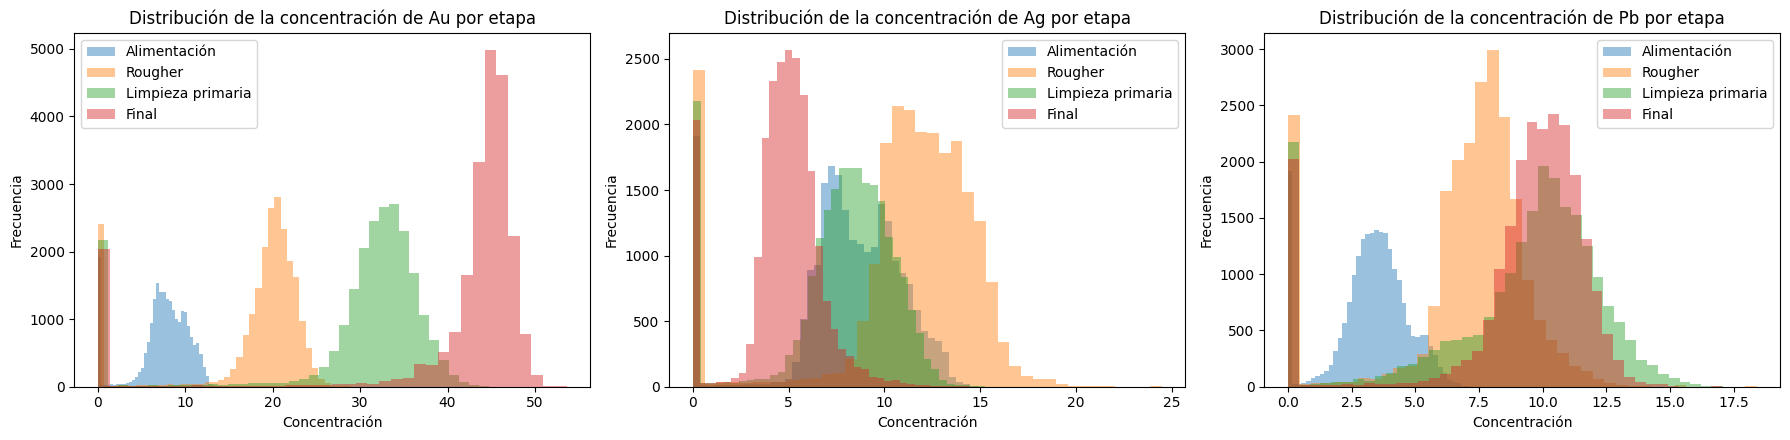

Concentración media por etapa:


,Alimentación,Rougher,Limpieza primaria,Final
Au,7.57,17.88,29.21,40.00
Ag,8.07,10.87,7.69,4.78
Pb,3.31,6.90,8.92,9.10


Porcentaje de valores exactamente iguales a 0:


,Alimentación,Rougher,Limpieza primaria,Final
Au,6.73,8.6,7.16,7.1
Ag,6.73,8.6,7.16,7.1
Pb,6.73,8.6,7.16,7.1



Au: aumenta de 7.57 (alimentación) a 40.00 (final), +429 %.
Ag: disminuye de 8.07 (alimentación) a 4.78 (final), -41 %.
Pb: aumenta de 3.31 (alimentación) a 9.10 (final), +175 %.


In [7]:
metals = {
    'Au': ['rougher.input.feed_au', 'rougher.output.concentrate_au',
           'primary_cleaner.output.concentrate_au', 'final.output.concentrate_au'],
    'Ag': ['rougher.input.feed_ag', 'rougher.output.concentrate_ag',
           'primary_cleaner.output.concentrate_ag', 'final.output.concentrate_ag'],
    'Pb': ['rougher.input.feed_pb', 'rougher.output.concentrate_pb',
           'primary_cleaner.output.concentrate_pb', 'final.output.concentrate_pb'],
}
etapas = ['Alimentación', 'Rougher', 'Limpieza primaria', 'Final']

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (metal, cols) in zip(axes, metals.items()):
    for col, etapa in zip(cols, etapas):
        ax.hist(full[col].dropna(), bins=40, alpha=0.45, label=etapa)
    ax.set_title(f'Distribución de la concentración de {metal} por etapa')
    ax.set_xlabel('Concentración')
    ax.set_ylabel('Frecuencia')
    ax.legend()
plt.tight_layout()
plt.show()

medias = pd.DataFrame({m: [full[c].mean() for c in cols] for m, cols in metals.items()}, index=etapas).T
ceros = pd.DataFrame({m: [(full[c] == 0).mean() * 100 for c in cols] for m, cols in metals.items()}, index=etapas).T

print("Concentración media por etapa:")
display(medias.round(2))
print("Porcentaje de valores exactamente iguales a 0:")
display(ceros.round(2))

print()
for m, cols in metals.items():
    ini, fin = full[cols[0]].mean(), full[cols[-1]].mean()
    sentido = "aumenta" if fin > ini else "disminuye"
    print(f"{m}: {sentido} de {ini:.2f} (alimentación) a {fin:.2f} (final), {(fin / ini - 1) * 100:+.0f} %.")

**Interpretación.**
- La tabla de medias muestra cómo se comporta cada metal a lo largo del proceso: el objetivo de la planta es **concentrar el oro** (su media debe subir etapa tras etapa), mientras que Ag y Pb se comportan distinto a Au, como indican las líneas impresas arriba. Cada metal sigue su propio patrón, por lo que no se pueden leer como un bloque.
- **El pico en 0 de los histogramas** no es una concentración real: una pulpa de mineral no tiene cero de oro, plata o plomo. Lo más probable es que sean **fallas de sensor, paros de planta o ausentes codificados como 0**. Estos ceros hacen que las medias queden más bajas de lo real, ensanchan la escala del eje y hacen que las etapas se vean más parecidas o más distintas de lo que son.
- **Impacto en el orden de los pasos:** estos registros deben tratarse **antes** de comparar etapas y de entrenar. Por eso en la sección 2.3 los detecto con la concentración total y en 2.4 repito esta comparación ya limpia.

### 2.2 Distribución del tamaño de partícula (train vs. test)

Si las distribuciones difieren mucho, la evaluación del modelo sobre `test` no sería fiable. Comparo las medias, medianas y la forma de la distribución. Como con tantos registros cualquier prueba estadística da un p-valor minúsculo, uso el **estadístico KS** (distancia máxima entre las distribuciones acumuladas) como medida del *tamaño* de la diferencia.

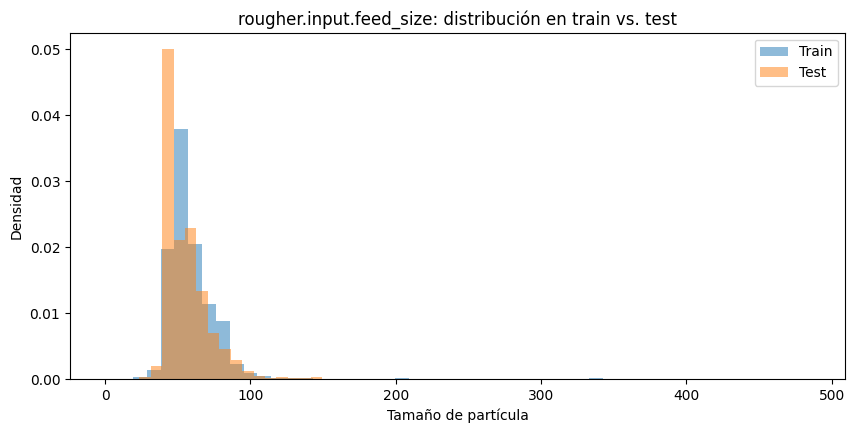

rougher.input.feed_size
  Media    train: 60.11 | test: 55.95 (-6.9 %)
  Mediana  train: 55.37 | test: 50.84
  KS = 0.249



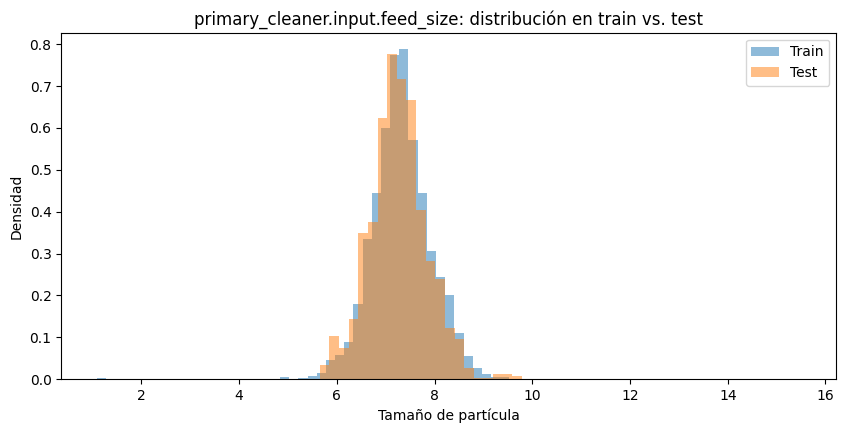

primary_cleaner.input.feed_size
  Media    train: 7.32 | test: 7.27 (-0.8 %)
  Mediana  train: 7.29 | test: 7.25
  KS = 0.059



In [8]:
particle_columns = ['rougher.input.feed_size', 'primary_cleaner.input.feed_size']

def comparar_tamano(col, graficar=True):
    a = train[col].dropna()
    b = test[col].dropna()
    ks = stats.ks_2samp(a, b)
    rel = (b.mean() - a.mean()) / a.mean() * 100

    if graficar:
        plt.figure(figsize=(10, 4.5))
        plt.hist(a, bins=50, alpha=0.5, density=True, label='Train')
        plt.hist(b, bins=50, alpha=0.5, density=True, label='Test')
        plt.title(f'{col}: distribución en train vs. test')
        plt.xlabel('Tamaño de partícula')
        plt.ylabel('Densidad')
        plt.legend()
        plt.show()

    print(f"{col}")
    print(f"  Media    train: {a.mean():.2f} | test: {b.mean():.2f} ({rel:+.1f} %)")
    print(f"  Mediana  train: {a.median():.2f} | test: {b.median():.2f}")
    print(f"  KS = {ks.statistic:.3f}\n")
    return {'media_train': a.mean(), 'media_test': b.mean(),
            'mediana_train': a.median(), 'mediana_test': b.median(),
            'rel': rel, 'ks': ks.statistic}

resumen_tamano = {}
for col in particle_columns:
    resumen_tamano[col] = comparar_tamano(col)

**Criterio de decisión.** Evalúo cada característica **por separado**. Considero que las distribuciones de train y test son *lo bastante similares* solo si KS < 0.10; entre 0.10 y 0.20 la diferencia es moderada y por encima de 0.20 es grande. Cada gráfico lleva en el título el nombre de la característica.

In [9]:
def veredicto_ks(ks):
    if ks < 0.10:
        return "SÍ son lo bastante similares"
    elif ks < 0.20:
        return "NO son del todo similares (diferencia moderada)"
    return "NO son lo bastante similares (diferencia grande)"

texto = "### Conclusión sobre el tamaño de partícula (train vs. test)\n\n"
for col, r in resumen_tamano.items():
    texto += (f"- **`{col}`**: media train {r['media_train']:.1f} vs. test {r['media_test']:.1f} "
              f"({r['rel']:+.1f} %), mediana {r['mediana_train']:.1f} vs. {r['mediana_test']:.1f}, "
              f"KS = {r['ks']:.3f}. **{veredicto_ks(r['ks'])}.**\n")

distintas = [c for c, r in resumen_tamano.items() if r['ks'] >= 0.10]
if distintas:
    lista = ", ".join(f"`{c}`" for c in distintas)
    texto += ("\n**Implicación:** en " + lista + " las distribuciones de train y test no coinciden lo suficiente: "
              "el modelo se evalúa con partículas de un tamaño distinto al que vio al entrenar. "
              "La evaluación en test sigue siendo válida porque el modelo no la usó, pero su sMAPE puede estar "
              "penalizado por este desfase y debe leerse con esa cautela. Lo retomo en el diagnóstico de la sección 3.6.")
else:
    texto += ("\n**Implicación:** en ambas características las distribuciones son lo bastante similares, "
              "así que el tamaño de partícula no es una fuente de desfase entre train y test.")
display(Markdown(texto))

### Conclusión sobre el tamaño de partícula (train vs. test)

- **`rougher.input.feed_size`**: media train 60.1 vs. test 56.0 (-6.9 %), mediana 55.4 vs. 50.8, KS = 0.249. **NO son lo bastante similares (diferencia grande).**
- **`primary_cleaner.input.feed_size`**: media train 7.3 vs. test 7.3 (-0.8 %), mediana 7.3 vs. 7.2, KS = 0.059. **SÍ son lo bastante similares.**

**Implicación:** en `rougher.input.feed_size` las distribuciones de train y test no coinciden lo suficiente: el modelo se evalúa con partículas de un tamaño distinto al que vio al entrenar. La evaluación en test sigue siendo válida porque el modelo no la usó, pero su sMAPE puede estar penalizado por este desfase y debe leerse con esa cautela. Lo retomo en el diagnóstico de la sección 3.6.

### 2.3 Concentración total por etapa y anomalías

Sumo las concentraciones de todas las sustancias (Au, Ag, Pb y sol) en la alimentación, el concentrado *rougher* y el concentrado final.

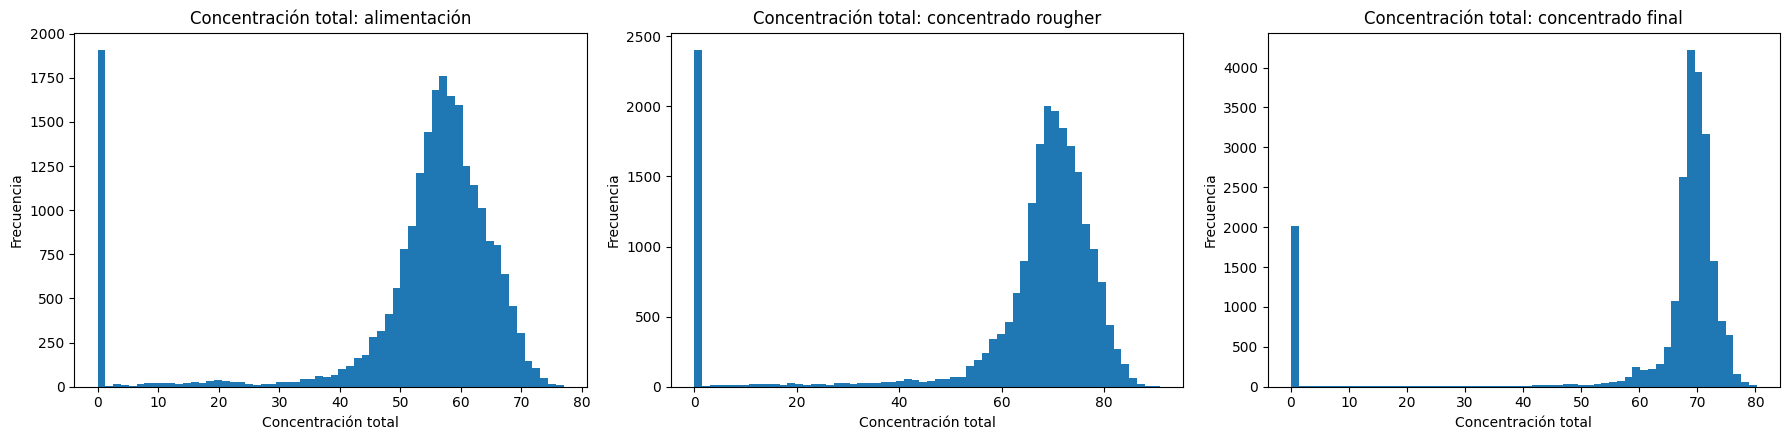

,feed_total,rougher_total,final_total
count,22618.00,22618.00,22630.00
mean,51.81,61.64,62.40
std,17.97,23.26,20.64
min,0.00,0.00,0.00
25%,51.39,63.39,67.04
50%,56.79,69.43,69.24
75%,61.43,74.03,71.14
max,76.98,90.96,80.21


In [10]:
stages = {
    'feed': ['rougher.input.feed_au', 'rougher.input.feed_ag', 'rougher.input.feed_pb', 'rougher.input.feed_sol'],
    'rougher': ['rougher.output.concentrate_au', 'rougher.output.concentrate_ag',
                'rougher.output.concentrate_pb', 'rougher.output.concentrate_sol'],
    'final': ['final.output.concentrate_au', 'final.output.concentrate_ag',
              'final.output.concentrate_pb', 'final.output.concentrate_sol'],
}
nombres_etapa = {'feed': 'alimentación', 'rougher': 'concentrado rougher', 'final': 'concentrado final'}

for stage, columns in stages.items():
    full[stage + '_total'] = full[columns].sum(axis=1, min_count=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, stage in zip(axes, stages):
    ax.hist(full[stage + '_total'].dropna(), bins=60)
    ax.set_title(f'Concentración total: {nombres_etapa[stage]}')
    ax.set_xlabel('Concentración total')
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

display(full[[s + '_total' for s in stages]].describe().round(2))

**Cómo defino una anomalía.** Las sustancias medidas son las que dominan la masa de cada flujo, así que la **suma total debería moverse en una banda relativamente estrecha** en cada etapa. Los registros con una suma cercana a **0** son imposibles físicamente (sensor caído o paro), y una **cola de valores muy por debajo de la masa principal** tampoco se explica por la variación normal del mineral: coincide con los mismos registros del pico en 0 y distorsiona tanto el análisis como el entrenamiento.

Para no fijar un número "a ojo", uso una regla estadística **por etapa**: marco como anómalo todo registro con total ≤ 1 o por debajo de

$$Q_1 - K \cdot IQR$$

calculado con los valores no nulos de esa etapa. Uso $K = 3$ (valor "muy atípico", más conservador que el 1.5 clásico) para quitar solo lo claramente fuera de la masa principal. Abajo muestro dónde cae el umbral y qué pasaría con otros valores de $K$.

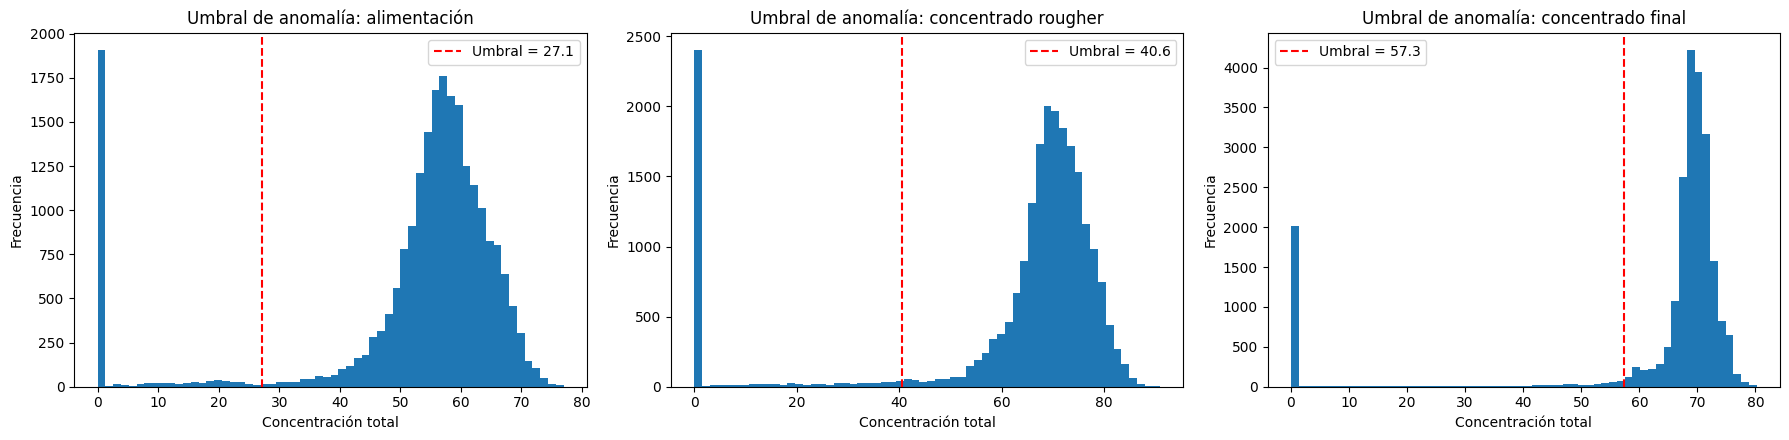

Sensibilidad al parámetro K (registros marcados en full):
  K = 1.5: 4863 registros (21.4 %)
  K = 2: 4366 registros (19.2 %)
  K = 3: 3802 registros (16.7 %)


In [11]:
K = 3

limites = {}
for stage in stages:
    s = full[stage + '_total']
    s_ok = s[s > 1]
    q1, q3 = s_ok.quantile([0.25, 0.75])
    limites[stage] = q1 - K * (q3 - q1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, stage in zip(axes, stages):
    ax.hist(full[stage + '_total'].dropna(), bins=60)
    ax.axvline(limites[stage], color='red', linestyle='--', label=f'Umbral = {limites[stage]:.1f}')
    ax.set_title(f'Umbral de anomalía: {nombres_etapa[stage]}')
    ax.set_xlabel('Concentración total')
    ax.set_ylabel('Frecuencia')
    ax.legend()
plt.tight_layout()
plt.show()

def mascara_anomalias(k):
    mask = pd.Series(False, index=full.index)
    for stage in stages:
        s = full[stage + '_total']
        s_ok = s[s > 1]
        q1, q3 = s_ok.quantile([0.25, 0.75])
        mask |= (s <= 1) | (s < q1 - k * (q3 - q1))
    return mask

print("Sensibilidad al parámetro K (registros marcados en full):")
for k in (1.5, 2, 3):
    n = mascara_anomalias(k).sum()
    print(f"  K = {k}: {n} registros ({n / len(full) * 100:.1f} %)")

In [12]:
anomaly_mask = mascara_anomalias(K)
anomaly_dates = full.loc[anomaly_mask, 'date']

print(f"Registros anómalos en full (K={K}): {len(anomaly_dates)} ({len(anomaly_dates) / len(full) * 100:.1f} %)")

n_train_antes, n_test_antes = len(train), len(test)
train = train[~train['date'].isin(anomaly_dates)].reset_index(drop=True)
test = test[~test['date'].isin(anomaly_dates)].reset_index(drop=True)

print(f"Train: {n_train_antes} -> {len(train)} ({n_train_antes - len(train)} eliminados)")
print(f"Test:  {n_test_antes} -> {len(test)} ({n_test_antes - len(test)} eliminados)")

Registros anómalos en full (K=3): 3802 (16.7 %)
Train: 14149 -> 13290 (859 eliminados)
Test:  5290 -> 4970 (320 eliminados)


**Interpretación y decisiones.**
- La cola baja de la distribución **sí se trata como anómala**: no refleja mineral distinto, sino mediciones fallidas o paros, y es justo el mismo fenómeno del pico en 0 de la sección 2.1.
- Elegí $K = 3$ porque elimina lo claramente atípico sin comerse variación operativa legítima; la tabla de sensibilidad muestra cuánto cambiaría el resultado con umbrales más estrictos. Si el porcentaje eliminado fuera alto (por ejemplo >5 %), subiría $K$ para ser más conservador.
- **La limpieza se aplica a train y a test** con las mismas fechas. En train, para que el modelo no aprenda de lecturas defectuosas; en test, para evaluar con la misma calidad de datos con la que se entrenó. (Limitación honesta: en producción también llegarían lecturas defectuosas, así que conviene un control de calidad de datos antes de usar el modelo.)

### 2.4 Verificación después de la limpieza

Repito la comparación de metales con los datos limpios y vuelvo a revisar el tamaño de partícula, para confirmar que quitar las anomalías corrigió lo que vimos en 2.1 y 2.2.

Concentración media ANTES de limpiar:


,Alimentación,Rougher,Limpieza primaria,Final
Au,7.57,17.88,29.21,40.00
Ag,8.07,10.87,7.69,4.78
Pb,3.31,6.90,8.92,9.10


Concentración media DESPUÉS de limpiar:


,Alimentación,Rougher,Limpieza primaria,Final
Au,8.35,20.34,32.17,44.66
Ag,8.88,12.37,8.51,5.28
Pb,3.65,7.82,9.83,10.12


Porcentaje de ceros DESPUÉS de limpiar:


,Alimentación,Rougher,Limpieza primaria,Final
Au,0.0,0.0,0.51,0.0
Ag,0.0,0.0,0.51,0.0
Pb,0.0,0.0,0.51,0.0


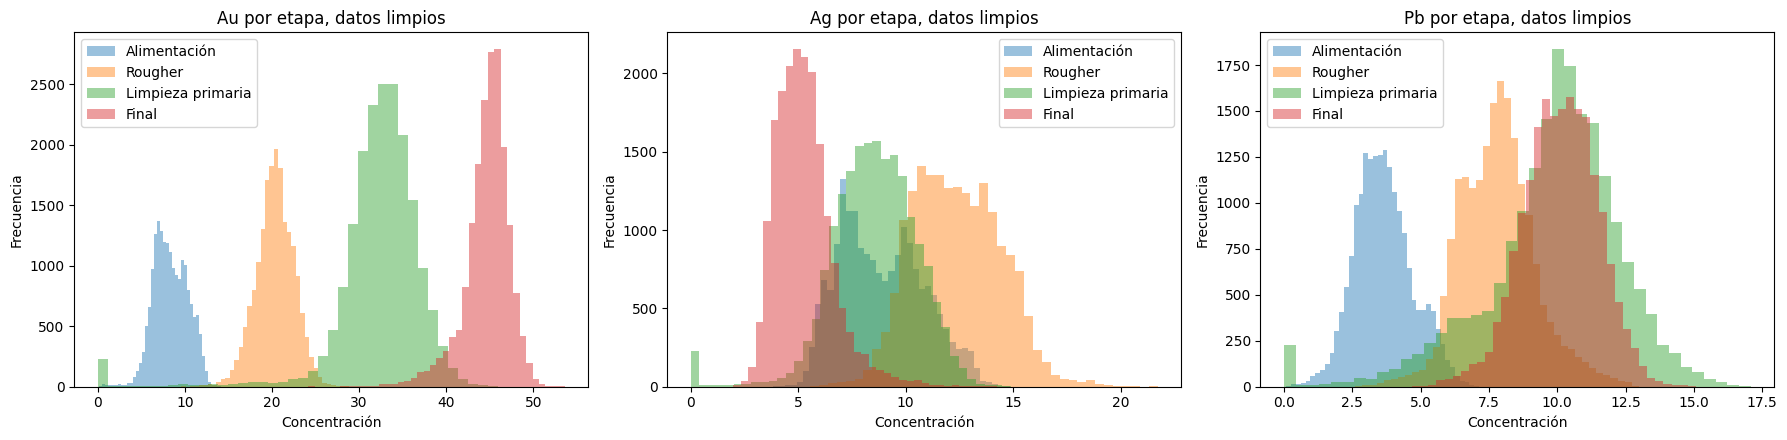

Tamaño de partícula tras la limpieza:

rougher.input.feed_size
  Media    train: 60.02 | test: 55.90 (-6.9 %)
  Mediana  train: 55.42 | test: 51.13
  KS = 0.247

primary_cleaner.input.feed_size
  Media    train: 7.33 | test: 7.26 (-0.8 %)
  Mediana  train: 7.30 | test: 7.25
  KS = 0.065



In [13]:
full_clean = full[~anomaly_mask]

antes = pd.DataFrame({m: [full[c].mean() for c in cols] for m, cols in metals.items()}, index=etapas).T
despues = pd.DataFrame({m: [full_clean[c].mean() for c in cols] for m, cols in metals.items()}, index=etapas).T
ceros_despues = pd.DataFrame({m: [(full_clean[c] == 0).mean() * 100 for c in cols] for m, cols in metals.items()}, index=etapas).T

print("Concentración media ANTES de limpiar:")
display(antes.round(2))
print("Concentración media DESPUÉS de limpiar:")
display(despues.round(2))
print("Porcentaje de ceros DESPUÉS de limpiar:")
display(ceros_despues.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (metal, cols) in zip(axes, metals.items()):
    for col, etapa in zip(cols, etapas):
        ax.hist(full_clean[col].dropna(), bins=40, alpha=0.45, label=etapa)
    ax.set_title(f'{metal} por etapa, datos limpios')
    ax.set_xlabel('Concentración')
    ax.set_ylabel('Frecuencia')
    ax.legend()
plt.tight_layout()
plt.show()

print("Tamaño de partícula tras la limpieza:\n")
resumen_tamano_limpio = {}
for col in particle_columns:
    resumen_tamano_limpio[col] = comparar_tamano(col, graficar=False)

In [14]:
texto = "### Resultado de la limpieza\n\n"
texto += (f"- Porcentaje medio de valores iguales a 0 en las columnas de metales: "
          f"{ceros.values.mean():.2f} % antes y {ceros_despues.values.mean():.2f} % después de limpiar.\n")

cambio = (despues - antes) / antes * 100
texto += "- Cambio de la concentración media por etapa tras limpiar:\n"
for m in cambio.index:
    texto += f"    - {m}: " + ", ".join(f"{e} {v:+.1f} %" for e, v in cambio.loc[m].items()) + "\n"

texto += "- Tamaño de partícula (KS antes -> después de limpiar):\n"
for col in particle_columns:
    texto += f"    - `{col}`: {resumen_tamano[col]['ks']:.3f} -> {resumen_tamano_limpio[col]['ks']:.3f}\n"

texto += f"- Registros conservados: train {len(train)}, test {len(test)}.\n"
display(Markdown(texto))

### Resultado de la limpieza

- Porcentaje medio de valores iguales a 0 en las columnas de metales: 7.40 % antes y 0.13 % después de limpiar.
- Cambio de la concentración media por etapa tras limpiar:
    - Au: Alimentación +10.4 %, Rougher +13.8 %, Limpieza primaria +10.1 %, Final +11.7 %
    - Ag: Alimentación +10.2 %, Rougher +13.8 %, Limpieza primaria +10.6 %, Final +10.4 %
    - Pb: Alimentación +10.3 %, Rougher +13.3 %, Limpieza primaria +10.2 %, Final +11.2 %
- Tamaño de partícula (KS antes -> después de limpiar):
    - `rougher.input.feed_size`: 0.249 -> 0.247
    - `primary_cleaner.input.feed_size`: 0.059 -> 0.065
- Registros conservados: train 13290, test 4970.


## 3. Construcción del modelo

### 3.1 Métrica: sMAPE

$$sMAPE = \frac{1}{N}\sum_{i=1}^{N}\frac{|y_i-\hat y_i|}{(|y_i|+|\hat y_i|)/2}\times 100$$

$$\text{sMAPE final} = 0.25\cdot sMAPE_{rougher} + 0.75\cdot sMAPE_{final}$$

Defino las funciones y un *scorer* negativo (sklearn maximiza, y aquí menor es mejor).

In [15]:
def smape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    result = np.zeros_like(denominator)
    np.divide(np.abs(y_true - y_pred), denominator, out=result, where=denominator != 0)
    return np.mean(result) * 100

def final_smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return 0.25 * smape(y_true[:, 0], y_pred[:, 0]) + 0.75 * smape(y_true[:, 1], y_pred[:, 1])

smape_scorer = make_scorer(final_smape, greater_is_better=False)

### 3.2 Preparación de características y objetivos

Uso solo las columnas comunes a train y test (sin objetivos ni fecha), numéricas y no vacías. Los datos están **ordenados por fecha**.

In [16]:
features = [c for c in train.columns
            if c in test.columns and c not in target_columns and c != 'date']

X_train = train[features].select_dtypes(include=np.number).replace([np.inf, -np.inf], np.nan)
X_train = X_train.dropna(axis=1, how='all')
X_test = test[X_train.columns].replace([np.inf, -np.inf], np.nan)

y_train = train[target_columns].values
y_test = test[target_columns].values

print("Características utilizadas:", X_train.shape[1])
print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

Características utilizadas: 52
Registros de entrenamiento: 13290
Registros de prueba: 4970


### 3.3 Validación cruzada sin fuga temporal

Los datos son una serie de tiempo y los registros cercanos son casi idénticos. Con `KFold(shuffle=True)`, el modelo puede entrenar con filas vecinas de las que valida, lo que puede hacer la validación optimista. Para evitarlo uso `TimeSeriesSplit`: en cada fold se entrena con el pasado y se valida con el futuro inmediato. Añado un pequeño `gap` entre ambos bloques para que las filas adyacentes no queden a los dos lados del corte.

In [17]:
GAP = 24   # filas que se descartan entre entrenamiento y validación (ajustable)
tscv = TimeSeriesSplit(n_splits=5, gap=GAP)

for i, (idx_tr, idx_va) in enumerate(tscv.split(X_train), start=1):
    print(f"Fold {i}: entrenamiento = {len(idx_tr):>5} filas | validación = {len(idx_va):>5} filas")

Fold 1: entrenamiento =  2191 filas | validación =  2215 filas
Fold 2: entrenamiento =  4406 filas | validación =  2215 filas
Fold 3: entrenamiento =  6621 filas | validación =  2215 filas
Fold 4: entrenamiento =  8836 filas | validación =  2215 filas
Fold 5: entrenamiento = 11051 filas | validación =  2215 filas


### 3.4 Modelos e hiperparámetros

Ridge y Random Forest se ajustan con `GridSearchCV` usando la misma validación temporal y la misma métrica; la regresión lineal no tiene hiperparámetros que ajustar y la línea base de la mediana se evalúa con la misma validación, de modo que los cuatro modelos son comparables:

| Modelo | Qué se ajusta | Preprocesamiento |
|---|---|---|
| Regresión lineal | nada | imputación + escalado |
| Ridge | `alpha` | imputación + escalado |
| Random Forest | `max_depth`, `min_samples_leaf` (100 árboles, `max_features=0.3`) | solo imputación |

El escalado **no afecta a los árboles**, así que solo lo uso en los modelos lineales. Añado también un **modelo de referencia** que predice la mediana, evaluado con la misma validación.

In [18]:
import time

imputer = lambda: SimpleImputer(strategy='median')

candidatos = {
    'Regresión lineal': (
        Pipeline([('imputer', imputer()), ('scaler', StandardScaler()), ('model', LinearRegression())]),
        {},
    ),
    'Ridge': (
        Pipeline([('imputer', imputer()), ('scaler', StandardScaler()), ('model', Ridge())]),
        {'model__alpha': [1, 10, 100, 1000]},
    ),
    'Random Forest': (
        Pipeline([('imputer', imputer()),
                  ('model', RandomForestRegressor(n_estimators=100, max_features=0.3,
                                                  random_state=RANDOM_STATE, n_jobs=-1))]),
        {'model__max_depth': [5, 10],
         'model__min_samples_leaf': [5, 20]},
    ),
}

dummy_pipe = Pipeline([('imputer', imputer()), ('model', DummyRegressor(strategy='median'))])

busquedas = {}
filas = []
for nombre, (pipe, grid) in candidatos.items():
    t0 = time.time()
    try:
        gs = GridSearchCV(pipe, grid, cv=tscv, scoring=smape_scorer, n_jobs=1)
        gs.fit(X_train, y_train)
        busquedas[nombre] = gs
        i = gs.best_index_
        filas.append({
            'Modelo': nombre,
            'sMAPE (validación)': -gs.best_score_,
            'Desv. entre folds': gs.cv_results_['std_test_score'][i],
            'Mejores parámetros': gs.best_params_,
        })
        print(f"{nombre}: sMAPE de validación = {-gs.best_score_:.3f}  ({time.time() - t0:.0f} s)")
    except Exception as e:
        print(f"{nombre}: ERROR -> {e}")
        filas.append({'Modelo': nombre, 'sMAPE (validación)': np.nan,
                      'Desv. entre folds': np.nan, 'Mejores parámetros': f'error: {e}'})

scores_dummy = cross_val_score(dummy_pipe, X_train, y_train, cv=tscv, scoring=smape_scorer, n_jobs=1)
filas.append({
    'Modelo': 'Referencia (mediana)',
    'sMAPE (validación)': -scores_dummy.mean(),
    'Desv. entre folds': scores_dummy.std(),
    'Mejores parámetros': {},
})

tabla_modelos = pd.DataFrame(filas).sort_values('sMAPE (validación)').reset_index(drop=True)
print("\nComparación con validación temporal (todos los modelos):")
display(tabla_modelos)

Regresión lineal: sMAPE de validación = 11.498  (1 s)
Ridge: sMAPE de validación = 9.231  (2 s)
Random Forest: sMAPE de validación = 8.945  (38 s)

Comparación con validación temporal (todos los modelos):


,Modelo,sMAPE (validación),Desv. entre folds,Mejores parámetros
0,Random Forest,8.944863,1.197612,"{'model__max_depth': 5, 'model__min_samples_le..."
1,Ridge,9.230833,1.242201,{'model__alpha': 1000}
2,Referencia (mediana),9.456077,0.848254,{}
3,Regresión lineal,11.498261,2.010702,{}


**Selección.** Entre los modelos reales (lineal, Ridge, Random Forest) elijo el de **menor sMAPE de validación**; el modelo de referencia solo se usa para comparar. El conjunto de prueba se toca **una sola vez**, al final.

In [19]:
reales = tabla_modelos[tabla_modelos['Modelo'] != 'Referencia (mediana)'].dropna(subset=['sMAPE (validación)'])
mejor_nombre = reales.iloc[0]['Modelo']
mejor_cv = reales.iloc[0]['sMAPE (validación)']
mejor_modelo = busquedas[mejor_nombre].best_estimator_

print("Mejor modelo según validación temporal:", mejor_nombre)
print("Parámetros:", busquedas[mejor_nombre].best_params_)

# Diagnóstico: ¿cuánto más optimista es la validación aleatoria?
kf_aleatorio = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_aleatoria = -cross_val_score(mejor_modelo, X_train, y_train, cv=kf_aleatorio,
                                scoring=smape_scorer, n_jobs=1).mean()

print(f"\nsMAPE con KFold aleatorio: {cv_aleatoria:.3f}")
print(f"sMAPE con TimeSeriesSplit (más conservador): {mejor_cv:.3f}")

Mejor modelo según validación temporal: Random Forest
Parámetros: {'model__max_depth': 5, 'model__min_samples_leaf': 5}

sMAPE con KFold aleatorio: 6.256
sMAPE con TimeSeriesSplit (más conservador): 8.945


### 3.5 Evaluación en el conjunto de prueba

Entreno el modelo elegido con **todo** el entrenamiento (ya lo hizo `GridSearchCV` con `refit=True`) y lo evalúo una vez en `test`, junto con el modelo de referencia.

In [20]:
pred_modelo = mejor_modelo.predict(X_test)

dummy_pipe.fit(X_train, y_train)
pred_dummy = dummy_pipe.predict(X_test)

resultados_test = pd.DataFrame({
    'sMAPE rougher': [smape(y_test[:, 0], pred_modelo[:, 0]), smape(y_test[:, 0], pred_dummy[:, 0])],
    'sMAPE final': [smape(y_test[:, 1], pred_modelo[:, 1]), smape(y_test[:, 1], pred_dummy[:, 1])],
    'sMAPE total': [final_smape(y_test, pred_modelo), final_smape(y_test, pred_dummy)],
}, index=[mejor_nombre, 'Referencia (mediana)'])

test_score = resultados_test.loc[mejor_nombre, 'sMAPE total']
dummy_test = resultados_test.loc['Referencia (mediana)', 'sMAPE total']

display(resultados_test.round(3))
print(f"Validación temporal ({mejor_nombre}): {mejor_cv:.3f}")
print(f"Prueba ({mejor_nombre}):               {test_score:.3f}")
print(f"Prueba (referencia mediana):          {dummy_test:.3f}")

,sMAPE rougher,sMAPE final,sMAPE total
Random Forest,3.923,7.030,6.253
Referencia (mediana),4.450,7.733,6.912


Validación temporal (Random Forest): 8.945
Prueba (Random Forest):               6.253
Prueba (referencia mediana):          6.912


### 3.6 Diagnóstico: ¿qué tan robusta es la diferencia entre el modelo y la mediana?

Comparo el modelo elegido con la línea base de la mediana en el conjunto de prueba y analizo qué factores podrían influir en esa diferencia. Reviso cuatro aspectos: (1) rendimiento por objetivo, (2) cambio en la distribución del objetivo entre train y test, (3) brecha entre validación y prueba y (4) qué variables usa el modelo.

In [21]:
print("1) Rendimiento por objetivo (sMAPE):")
display(resultados_test.round(3))

print("\n2) Distribución de los objetivos (media / desviación estándar):")
desfase = pd.DataFrame({
    'train media': train[target_columns].mean(),
    'test media': test[target_columns].mean(),
    'train desv.': train[target_columns].std(),
    'test desv.': test[target_columns].std(),
})
display(desfase.round(2))

print(f"3) Brecha validación -> prueba: {test_score - mejor_cv:+.3f} puntos de sMAPE")

print("\n4) Características más importantes del modelo elegido:")
modelo_final = mejor_modelo.named_steps['model']
if hasattr(modelo_final, 'feature_importances_'):
    imp = pd.Series(modelo_final.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    display(imp.head(10).round(4))
elif hasattr(modelo_final, 'coef_'):
    coefs = pd.Series(np.abs(modelo_final.coef_).mean(axis=0), index=X_train.columns).sort_values(ascending=False)
    display(coefs.head(10).round(4))

mejora = (dummy_test - test_score) / dummy_test * 100
if test_score < dummy_test:
    print(f"\nEl modelo supera a la referencia en prueba por {mejora:.1f} %.")
else:
    print(f"\nEl modelo NO supera a la referencia en prueba (queda {-mejora:.1f} % peor).")

1) Rendimiento por objetivo (sMAPE):


,sMAPE rougher,sMAPE final,sMAPE total
Random Forest,3.923,7.030,6.253
Referencia (mediana),4.450,7.733,6.912



2) Distribución de los objetivos (media / desviación estándar):


,train media,test media,train desv.,test desv.
rougher.output.recovery,84.68,86.97,7.55,4.79
final.output.recovery,66.97,69.27,8.73,6.67


3) Brecha validación -> prueba: -2.692 puntos de sMAPE

4) Características más importantes del modelo elegido:


rougher.input.feed_ag                       0.1568
primary_cleaner.input.sulfate               0.1401
secondary_cleaner.state.floatbank4_b_air    0.1031
rougher.input.feed_au                       0.0503
rougher.state.floatbank10_a_air             0.0476
rougher.state.floatbank10_c_air             0.0443
rougher.state.floatbank10_d_air             0.0401
secondary_cleaner.state.floatbank4_a_air    0.0384
secondary_cleaner.state.floatbank2_a_air    0.0334
secondary_cleaner.state.floatbank3_a_air    0.0327
dtype: float64


El modelo supera a la referencia en prueba por 9.5 %.


In [22]:
r_mod = resultados_test.loc[mejor_nombre]
r_dum = resultados_test.loc['Referencia (mediana)']
dummy_cv = tabla_modelos.loc[tabla_modelos['Modelo'] == 'Referencia (mediana)', 'sMAPE (validación)'].iloc[0]

# Umbrales usados en este diagnóstico (explícitos y ajustables)
UMBRAL_NIVEL = 2             # % de cambio en la media del objetivo entre train y test que considero relevante
UMBRAL_DESV = 10             # % de caída en la desviación estándar que considero relevante
UMBRAL_MEDIANA = 0.5         # puntos de sMAPE: cambio de la mediana entre validación y prueba que considero relevante
UMBRAL_CONCENTRACION = 0.5   # fracción del peso total acumulada por las 3 variables principales
UMBRAL_KS = 0.10             # mismo criterio de similitud usado en la sección 2.2
UMBRAL_MEJORA = 10           # % de mejora sobre la mediana a partir del cual la ventaja se considera clara

# Pesos de las variables
modelo_final = mejor_modelo.named_steps['model']
if hasattr(modelo_final, 'feature_importances_'):
    pesos = pd.Series(modelo_final.feature_importances_, index=X_train.columns)
else:
    pesos = pd.Series(np.abs(modelo_final.coef_).mean(axis=0), index=X_train.columns)
pesos = (pesos / pesos.sum()).sort_values(ascending=False)
top3 = pesos.head(3)

def mejor_peor(a, b):
    return "mejor" if a < b else "peor"

mejora = (dummy_test - test_score) / dummy_test * 100

texto = "### Diagnóstico con los resultados reales\n\n"

# 1) Rendimiento por objetivo
texto += (f"1. **Rendimiento por objetivo.** En *rougher* el modelo obtiene sMAPE {r_mod['sMAPE rougher']:.2f} "
          f"frente a {r_dum['sMAPE rougher']:.2f} de la mediana "
          f"({mejor_peor(r_mod['sMAPE rougher'], r_dum['sMAPE rougher'])}). "
          f"En *final* obtiene {r_mod['sMAPE final']:.2f} frente a {r_dum['sMAPE final']:.2f} "
          f"({mejor_peor(r_mod['sMAPE final'], r_dum['sMAPE final'])}). La etapa final pesa 75 % de la métrica.\n")

# 2) Cambio del objetivo entre train y test
texto += "2. **Cambio en el objetivo entre train y test.**\n"
cambio_media, cambio_desv = [], []
for t in target_columns:
    m_tr, m_te = train[t].mean(), test[t].mean()
    s_tr, s_te = train[t].std(), test[t].std()
    cm = (m_te - m_tr) / m_tr * 100
    cs = (s_te - s_tr) / s_tr * 100
    cambio_media.append(cm)
    cambio_desv.append(cs)
    texto += (f"    - `{t}`: media {m_tr:.1f} -> {m_te:.1f} ({cm:+.1f} %); "
              f"desviación estándar {s_tr:.1f} -> {s_te:.1f} ({cs:+.1f} %).\n")

# 3) Brecha validación-prueba
delta_mod = test_score - mejor_cv
delta_dum = dummy_test - dummy_cv
mismo_sentido = delta_mod * delta_dum > 0
texto += (f"3. **Brecha entre validación y prueba.** El modelo pasa de {mejor_cv:.2f} en validación a {test_score:.2f} "
          f"en prueba ({delta_mod:+.2f}); la mediana pasa de {dummy_cv:.2f} a {dummy_test:.2f} ({delta_dum:+.2f}). ")
if mismo_sentido:
    sentido = "mejoran" if delta_mod < 0 else "empeoran"
    texto += (f"Ambos {sentido} en prueba, lo que sugiere que el periodo de prueba podría ser distinto "
              "(más fácil o más difícil de predecir) al de entrenamiento, aunque una sola partición de prueba "
              "no basta para demostrarlo.\n")
else:
    texto += "Se mueven en sentidos distintos, así que el cambio de periodo por sí solo no explicaría el resultado del modelo.\n"

# 4) Variables principales
texto += ("4. **Variables más importantes del modelo.** "
          + ", ".join(f"`{k}` ({v * 100:.1f} %)" for k, v in top3.items())
          + f". Las tres suman {top3.sum() * 100:.1f} % del peso total.\n")

# Factores que podrían contribuir (hipótesis, con su umbral explícito)
causas = []
if max(abs(c) for c in cambio_media) > UMBRAL_NIVEL:
    causas.append(f"la media de la recuperación cambió más de {UMBRAL_NIVEL} % entre train y test")
if min(cambio_desv) < -UMBRAL_DESV:
    causas.append(f"la variabilidad del objetivo en prueba es más de {UMBRAL_DESV} % menor que en train")
if mismo_sentido and abs(delta_dum) > UMBRAL_MEDIANA:
    causas.append(f"la mediana también cambia más de {UMBRAL_MEDIANA} puntos de sMAPE entre validación y prueba")
if top3.sum() > UMBRAL_CONCENTRACION:
    causas.append(f"las tres variables principales concentran más del {UMBRAL_CONCENTRACION * 100:.0f} % del peso del modelo")
desfasadas = [c for c, r in resumen_tamano.items() if r['ks'] >= UMBRAL_KS]
if desfasadas:
    causas.append("el tamaño de partícula difiere entre train y test en "
                  + ", ".join(f"`{c}`" for c in desfasadas) + f" (KS >= {UMBRAL_KS})")

texto += "\n**Conclusión del diagnóstico (hipótesis, no causas demostradas):** "
if test_score < dummy_test:
    calificativo = "clara" if mejora >= UMBRAL_MEJORA else "modesta"
    texto += (f"el modelo mejora a la mediana en prueba ({test_score:.2f} vs. {dummy_test:.2f}, {mejora:.1f} % menos), "
              f"una ventaja {calificativo} que proviene de una sola partición de prueba. ")
else:
    texto += (f"el modelo no mejora a la mediana en prueba ({test_score:.2f} vs. {dummy_test:.2f}). ")
if causas:
    texto += ("Estos factores podrían contribuir a la diferencia entre validación y prueba: "
              + "; ".join(causas) + ". ")

# Frase propia con las cifras reales
if all(c < 0 for c in cambio_desv) and test_score < mejor_cv:
    texto += (f"\n\n**Lectura de las cifras.** En prueba la desviación estándar del objetivo baja "
              f"({cambio_desv[0]:+.1f} % en rougher y {cambio_desv[1]:+.1f} % en final) y las medias cambian "
              f"{cambio_media[0]:+.1f} % y {cambio_media[1]:+.1f} %. Un conjunto de prueba menos variable es más fácil de predecir, "
              f"lo que podría ayudar a explicar por qué el sMAPE de prueba ({test_score:.2f}) es menor que el de validación "
              f"({mejor_cv:.2f}). Conviene relacionarlo con la ventaja del modelo sobre la mediana ({mejora:.1f} %): "
              "como la mediana también cambia, parte de la mejora aparente en prueba podría deberse al periodo y no solo al modelo.")
display(Markdown(texto))

### Diagnóstico con los resultados reales

1. **Rendimiento por objetivo.** En *rougher* el modelo obtiene sMAPE 3.92 frente a 4.45 de la mediana (mejor). En *final* obtiene 7.03 frente a 7.73 (mejor). La etapa final pesa 75 % de la métrica.
2. **Cambio en el objetivo entre train y test.**
    - `rougher.output.recovery`: media 84.7 -> 87.0 (+2.7 %); desviación estándar 7.6 -> 4.8 (-36.6 %).
    - `final.output.recovery`: media 67.0 -> 69.3 (+3.4 %); desviación estándar 8.7 -> 6.7 (-23.6 %).
3. **Brecha entre validación y prueba.** El modelo pasa de 8.94 en validación a 6.25 en prueba (-2.69); la mediana pasa de 9.46 a 6.91 (-2.54). Ambos mejoran en prueba, lo que sugiere que el periodo de prueba podría ser distinto (más fácil o más difícil de predecir) al de entrenamiento, aunque una sola partición de prueba no basta para demostrarlo.
4. **Variables más importantes del modelo.** `rougher.input.feed_ag` (15.7 %), `primary_cleaner.input.sulfate` (14.0 %), `secondary_cleaner.state.floatbank4_b_air` (10.3 %). Las tres suman 40.0 % del peso total.

**Conclusión del diagnóstico (hipótesis, no causas demostradas):** el modelo mejora a la mediana en prueba (6.25 vs. 6.91, 9.5 % menos), una ventaja modesta que proviene de una sola partición de prueba. Estos factores podrían contribuir a la diferencia entre validación y prueba: la media de la recuperación cambió más de 2 % entre train y test; la variabilidad del objetivo en prueba es más de 10 % menor que en train; la mediana también cambia más de 0.5 puntos de sMAPE entre validación y prueba; el tamaño de partícula difiere entre train y test en `rougher.input.feed_size` (KS >= 0.1). 

**Lectura de las cifras.** En prueba la desviación estándar del objetivo baja (-36.6 % en rougher y -23.6 % en final) y las medias cambian +2.7 % y +3.4 %. Un conjunto de prueba menos variable es más fácil de predecir, lo que podría ayudar a explicar por qué el sMAPE de prueba (6.25) es menor que el de validación (8.94). Conviene relacionarlo con la ventaja del modelo sobre la mediana (9.5 %): como la mediana también cambia, parte de la mejora aparente en prueba podría deberse al periodo y no solo al modelo.

## 4. Conclusiones

In [23]:
mejora_final = (dummy_test - test_score) / dummy_test * 100
ks_feed = resumen_tamano_limpio['rougher.input.feed_size']['ks']

if test_score < dummy_test:
    leccion_resultado = (f"El {mejor_nombre} obtiene un sMAPE de {test_score:.2f} en prueba frente a {dummy_test:.2f} "
                         f"de la mediana, una mejora de {mejora_final:.1f} % medida en una sola partición de prueba.")
else:
    leccion_resultado = (f"El {mejor_nombre} obtiene un sMAPE de {test_score:.2f} en prueba, sin mejorar a la mediana "
                         f"({dummy_test:.2f}).")

if ks_feed >= 0.10:
    leccion_tamano = (f"`rougher.input.feed_size` sigue difiriendo entre entrenamiento y prueba después de la limpieza "
                      f"(KS = {ks_feed:.2f}), lo que afecta cuánta confianza merece la puntuación de prueba.")
else:
    leccion_tamano = (f"`rougher.input.feed_size` es similar entre entrenamiento y prueba después de la limpieza "
                      f"(KS = {ks_feed:.2f}).")

texto = f"""### Lo que aprendí del análisis

1. **Calidad de los datos.** Los ceros y la cola baja de la concentración total parecen mediciones fallidas, no mineral distinto; los eliminé con un umbral por etapa, aplicado a train y test antes de comparar y modelar.
2. **Sin fugas de información.** Las columnas `output` y `calculation` solo existen después del proceso; el modelo usa únicamente entradas y condiciones de operación comunes a train y test.
3. **Validación.** En series de tiempo, `KFold` con mezcla aleatoria dio un sMAPE de {cv_aleatoria:.2f} y `TimeSeriesSplit` con `gap` dio {mejor_cv:.2f}. La validación temporal es la estimación más conservadora; en prueba el modelo obtuvo {test_score:.2f}, así que no puedo afirmar que sea la más exacta.
4. **Comparación.** Ridge y Random Forest se ajustaron con `GridSearchCV` usando la misma validación temporal, y se compararon con la regresión lineal y con una línea base de mediana.
5. **Resultado.** {leccion_resultado}
6. **Tamaño de partícula.** {leccion_tamano}
"""
display(Markdown(texto))

### Lo que aprendí del análisis

1. **Calidad de los datos.** Los ceros y la cola baja de la concentración total parecen mediciones fallidas, no mineral distinto; los eliminé con un umbral por etapa, aplicado a train y test antes de comparar y modelar.
2. **Sin fugas de información.** Las columnas `output` y `calculation` solo existen después del proceso; el modelo usa únicamente entradas y condiciones de operación comunes a train y test.
3. **Validación.** En series de tiempo, `KFold` con mezcla aleatoria dio un sMAPE de 6.26 y `TimeSeriesSplit` con `gap` dio 8.94. La validación temporal es la estimación más conservadora; en prueba el modelo obtuvo 6.25, así que no puedo afirmar que sea la más exacta.
4. **Comparación.** Ridge y Random Forest se ajustaron con `GridSearchCV` usando la misma validación temporal, y se compararon con la regresión lineal y con una línea base de mediana.
5. **Resultado.** El Random Forest obtiene un sMAPE de 6.25 en prueba frente a 6.91 de la mediana, una mejora de 9.5 % medida en una sola partición de prueba.
6. **Tamaño de partícula.** `rougher.input.feed_size` sigue difiriendo entre entrenamiento y prueba después de la limpieza (KS = 0.25), lo que afecta cuánta confianza merece la puntuación de prueba.
